# Overnight versus Daytime Predictability of the Last Half Hour, CL 2021–2026 (#31)

This notebook collects the outputs of `src/analyze_on_day.py`: the single-component and joint models of LH on ON and DAY next to the paper's ROD model, the equality test, the incremental out-of-sample comparisons, and the stability checks. It reads only the files the script writes and computes nothing the script does not. Run the script first, from the repository root:

```bash
python -m src.analyze_on_day --config config/on_day.yaml
```

The write-up is `reports/on_day_results.md`. Slopes are × 100 with Newey-West standard errors; OOS R² is in percent.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "reports/tables").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

manifest = json.loads((tables / "on_day.manifest.json").read_text())
regressions = pd.read_csv(tables / "on_day_regressions.csv")
models = pd.read_csv(tables / "on_day_models.csv")
sensitivity = pd.read_csv(tables / "on_day_oos_sensitivity.csv")
by_year = pd.read_csv(tables / "on_day_by_year.csv")
robustness = pd.read_csv(tables / "on_day_robustness.csv")
robustness_models = pd.read_csv(tables / "on_day_robustness_models.csv")

pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
MODELS = {"on": "LH ~ ON", "day": "LH ~ DAY", "on_day": "LH ~ ON + DAY", "rod": "LH ~ ROD"}


def estimate(frame: pd.DataFrame, value: str, error: str) -> pd.Series:
	return frame.apply(lambda row: f"{row[value]:.2f} ({row[error]:.2f})" if pd.notna(row[value]) else "", axis=1)

## 1. Sample and slopes

The four models on the 1,436 sample dates. The response per standard deviation puts ON and DAY, which have different spreads, on the same footing.

In [2]:
sd = manifest["sample"]["sd_pct"]
pd.Series(
	{
		"trade dates": manifest["sample"]["observations"],
		"dates": manifest["sample"]["dates"],
		"Newey-West lags": manifest["hac_lags_used"],
		"first out-of-sample forecast": manifest["sample"]["first_oos_forecast"],
		"SD of LH / ON / DAY / ROD (%)": f"{sd['y']:.2f} / {sd['on']:.2f} / {sd['day']:.2f} / {sd['rod']:.2f}",
		"corr(ON, DAY)": f"{manifest['sample']['corr_on_day']:.3f}",
		"pre-expiry roll: dates with another contract": manifest["pre_expiry_roll"]["contract_changed_dates"],
	},
	name="value",
).to_frame()

,value
trade dates,1436
dates,2021-01-04 to 2026-10-07
Newey-West lags,7
first out-of-sample forecast,2023-01-04
SD of LH / ON / DAY / ROD (%),0.47 / 1.94 / 1.66 / 2.48
"corr(ON, DAY)",-0.055
pre-expiry roll: dates with another contract,127


In [3]:
slopes = regressions[regressions["term"].ne("const")].assign(model=lambda frame: frame["model"].map(MODELS), estimate=estimate(regressions, "coef_x100", "se_x100"))
slopes[["model", "term", "estimate", "ci_low_x100", "ci_high_x100", "t_stat", "p_value", "standardized", "response_bps_per_sd", "adj_r2_pct"]].rename(columns={"estimate": "slope x 100 (SE)"})

,model,term,slope x 100 (SE),ci_low_x100,ci_high_x100,t_stat,p_value,standardized,response_bps_per_sd,adj_r2_pct
1,LH ~ ON,on,-1.18 (1.01),-3.151,0.798,-1.168,0.243,-0.049,-2.279,0.167
3,LH ~ DAY,day,-1.76 (1.42),-4.532,1.018,-1.241,0.215,-0.062,-2.917,0.317
5,LH ~ ON + DAY,on,-1.26 (1.01),-3.246,0.721,-1.248,0.212,-0.052,-2.446,0.519
6,LH ~ ON + DAY,day,-1.84 (1.43),-4.643,0.968,-1.284,0.199,-0.065,-3.051,0.519
8,LH ~ ROD,rod,-1.46 (0.97),-3.349,0.435,-1.510,0.131,-0.077,-3.614,0.524


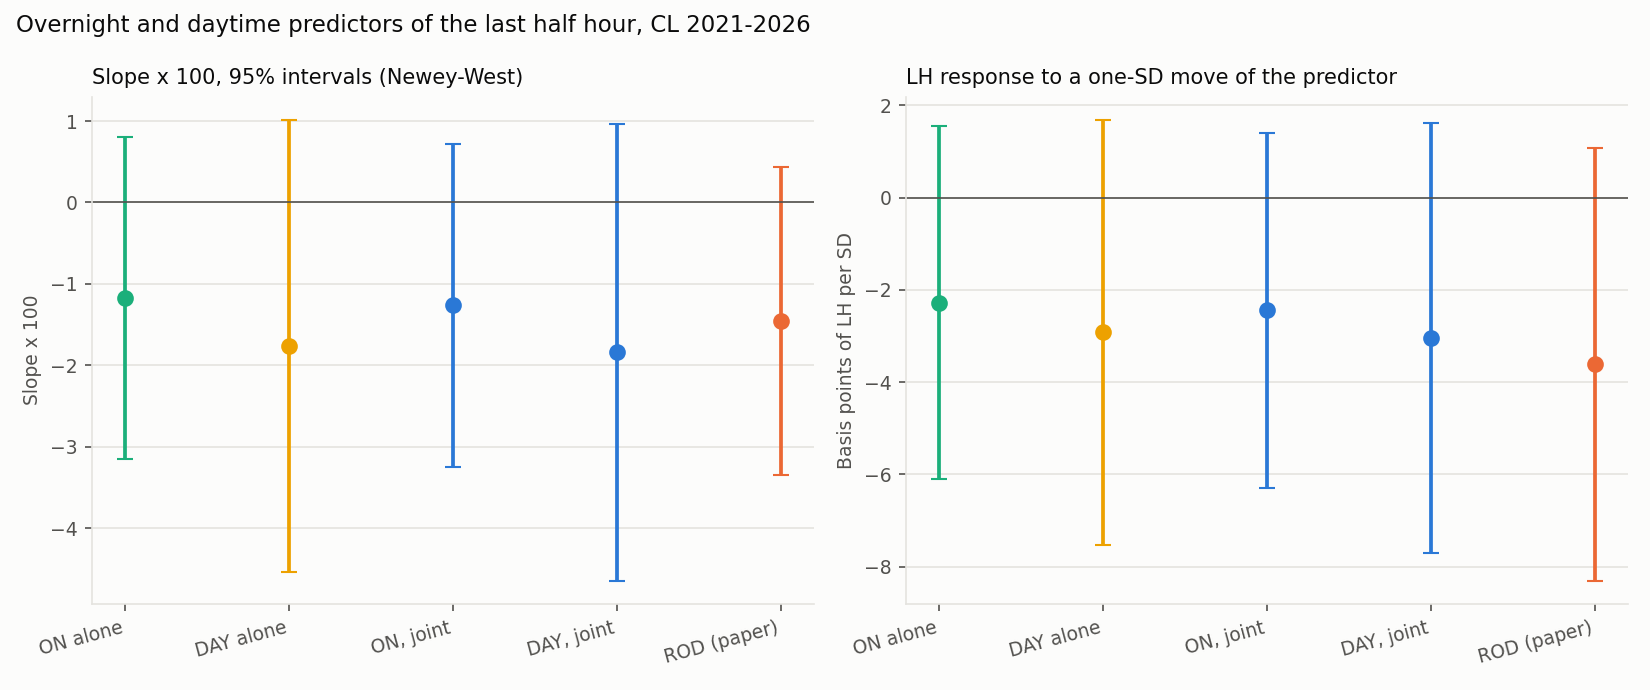

In [4]:
display(Image(filename=figures / "on_day_slopes.png", width=950))

## 2. Equality test, incremental information and out of sample

The Wald test of β_ON = β_DAY, the adjusted R² and the expanding-window OOS R² of each model against the historical mean, and the joint model against each single model it nests (Clark-West).

In [5]:
models.assign(model=models["model"].map(MODELS))[["model", "n", "adj_r2_pct", "oos_forecasts", "oos_r2_pct", "clark_west_t", "clark_west_p", "equality_difference_x100", "equality_se_x100", "equality_wald", "equality_p", "adj_r2_gain_vs_on_pct", "oos_r2_vs_on_pct", "clark_west_p_vs_on", "adj_r2_gain_vs_day_pct", "oos_r2_vs_day_pct", "clark_west_p_vs_day"]]

,model,n,adj_r2_pct,oos_forecasts,oos_r2_pct,clark_west_t,clark_west_p,equality_difference_x100,equality_se_x100,equality_wald,equality_p,adj_r2_gain_vs_on_pct,oos_r2_vs_on_pct,clark_west_p_vs_on,adj_r2_gain_vs_day_pct,oos_r2_vs_day_pct,clark_west_p_vs_day
0,LH ~ ON,1436,0.167,936,-0.495,-0.104,0.541,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LH ~ DAY,1436,0.317,936,0.124,0.783,0.217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LH ~ ON + DAY,1436,0.519,936,-0.294,0.335,0.369,0.575,1.428,0.162,0.687,0.353,0.201,0.152,0.202,-0.418,0.480
3,LH ~ ROD,1436,0.524,936,0.368,1.002,0.158,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
sensitivity.pivot(index=["min_train_obs", "first_forecast"], columns="model", values="oos_r2_pct").rename(columns=MODELS)

,model,LH ~ DAY,LH ~ ON,LH ~ ON + DAY,LH ~ ROD
min_train_obs,first_forecast,,,,
250,2022-01-03,-0.200,-0.548,-0.685,-0.020
500,2023-01-04,0.124,-0.495,-0.294,0.368
750,2024-01-05,0.311,-0.313,0.080,0.494
1000,2025-01-08,0.398,-0.257,0.234,0.582


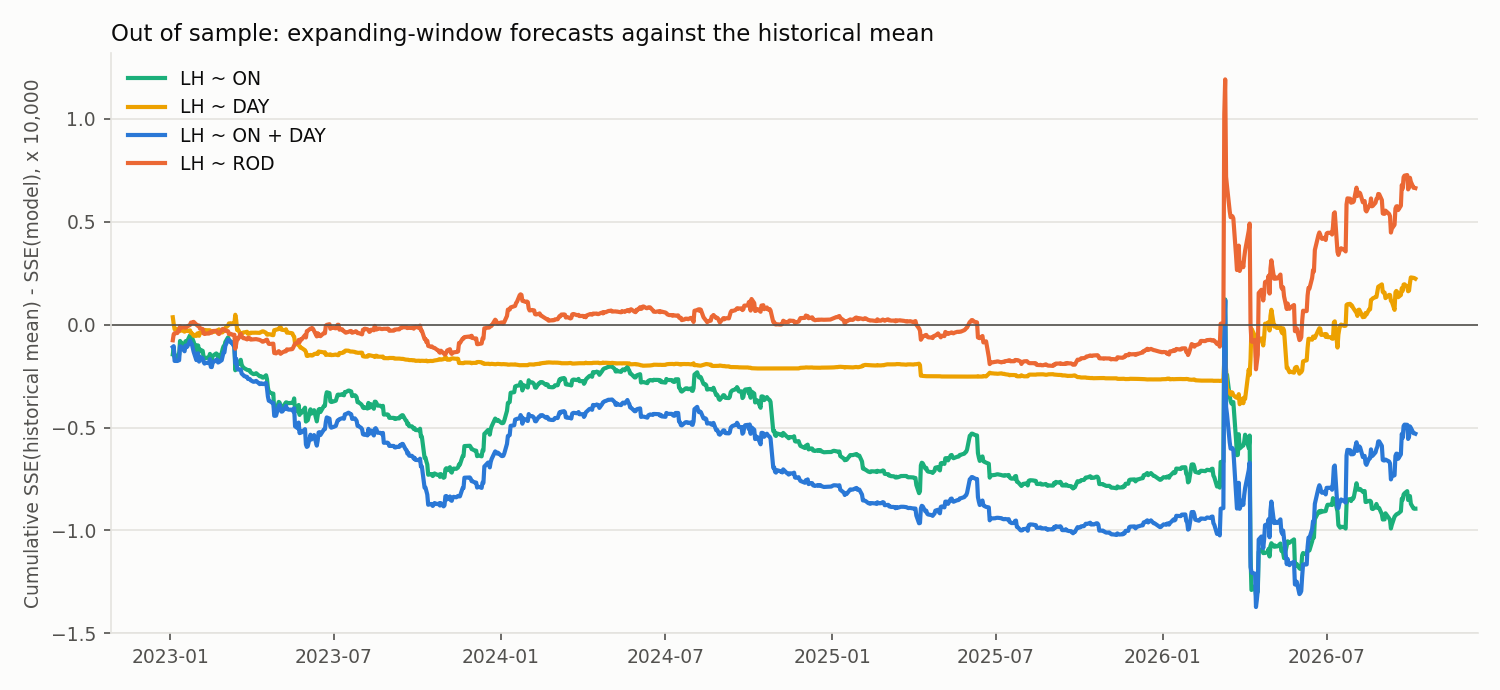

In [7]:
display(Image(filename=figures / "on_day_oos.png", width=950))

## 3. Over time

Calendar-year slopes of the joint model and the rolling 252-day estimates.

In [8]:
years = by_year[by_year["model"].eq("on_day") & by_year["term"].ne("const")].assign(estimate=estimate(by_year, "coef_x100", "se_x100"))
years.pivot(index="year", columns="term", values="estimate").rename(columns={"on": "ON slope x 100 (SE)", "day": "DAY slope x 100 (SE)"})

term,DAY slope x 100 (SE),ON slope x 100 (SE)
year,,
2021,1.26 (2.36),-4.23 (2.18)
2022,0.34 (2.11),-1.83 (2.41)
2023,-1.92 (1.71),1.06 (2.09)
2024,-1.61 (1.49),0.29 (1.99)
2025,2.08 (2.34),0.39 (1.33)
2026,-9.65 (4.00),-1.54 (1.74)


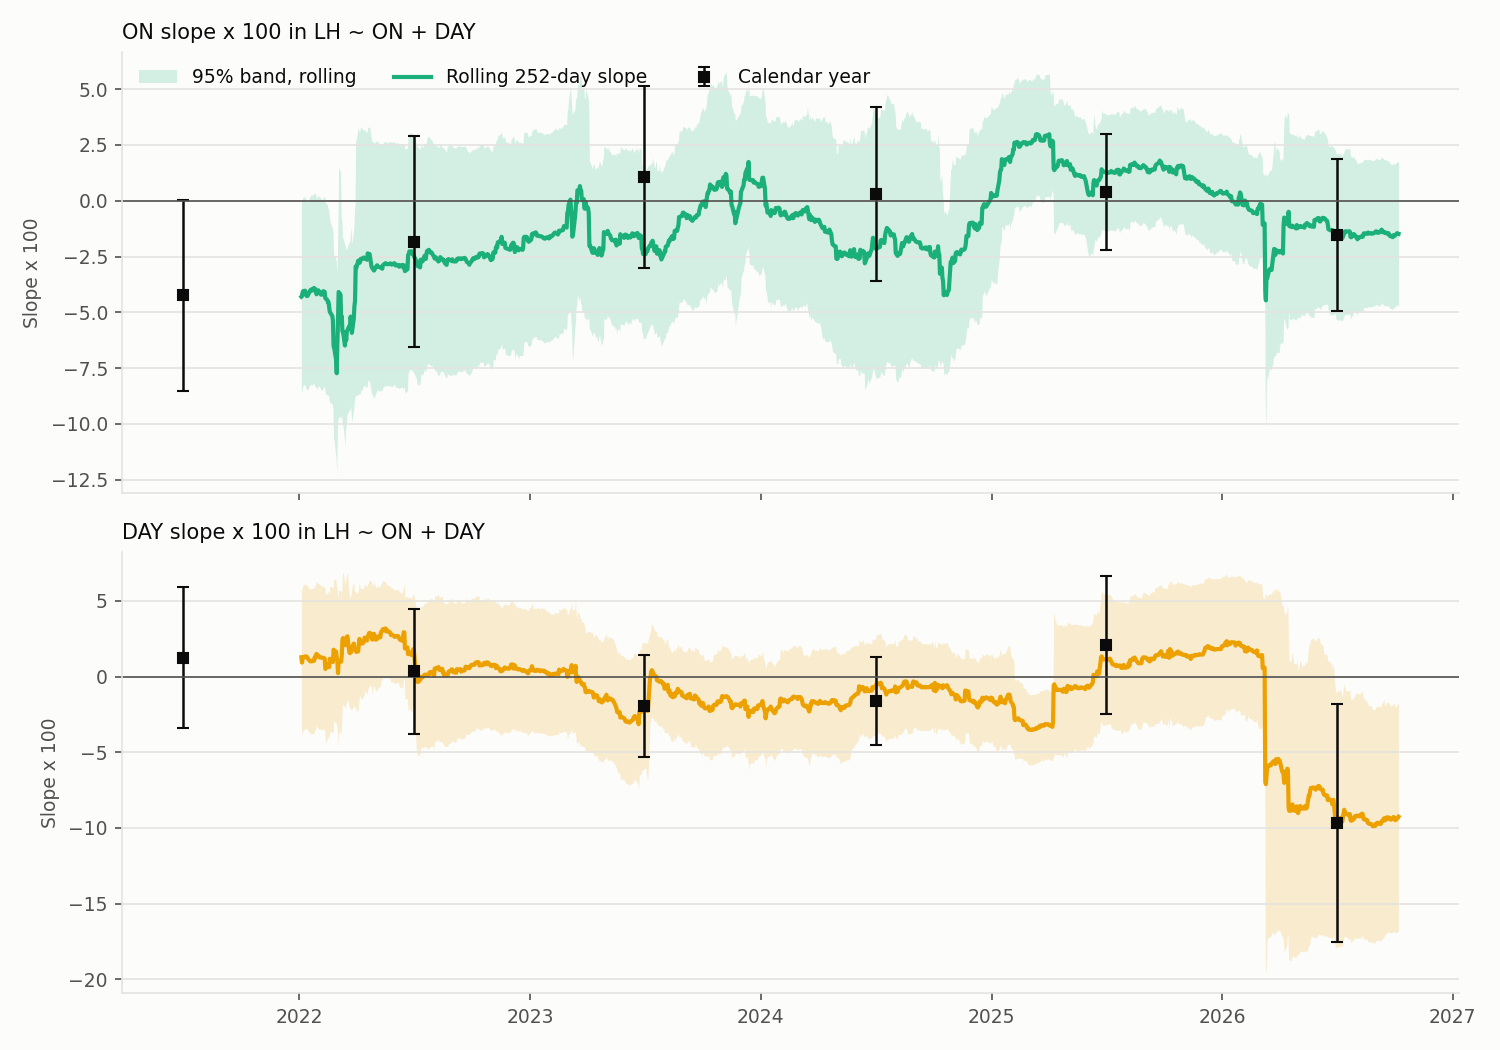

In [9]:
display(Image(filename=figures / "on_day_over_time.png", width=950))

## 4. Robustness

Joint-model slopes under other Newey-West lags, log returns, the pre-expiry roll rule and excluded dates, with the equality test and the out-of-sample statistics where they were run.

In [10]:
terms = robustness[robustness["model"].eq("on_day") & robustness["term"].ne("const")].assign(estimate=estimate(robustness, "coef_x100", "se_x100"))
wide = terms.pivot(index="variant", columns="term", values="estimate").rename(columns={"on": "ON (SE)", "day": "DAY (SE)"})
wide.join(robustness_models[robustness_models["model"].eq("on_day")].set_index("variant")[["dropped", "n", "adj_r2_pct", "equality_p", "oos_r2_pct", "oos_r2_vs_on_pct", "oos_r2_vs_day_pct"]])

,DAY (SE),ON (SE),dropped,n,adj_r2_pct,equality_p,oos_r2_pct,oos_r2_vs_on_pct,oos_r2_vs_day_pct
variant,,,,,,,,,
exclude_2026_03_10,-0.63 (0.93),-0.73 (0.89),1,1435,-0.001,0.934,-0.834,-0.095,-0.697
exclude_after_non_trading_days,-1.73 (1.81),-0.98 (1.19),304,1132,0.310,0.653,-1.001,-0.648,-0.310
exclude_degraded_dates,-1.91 (1.44),-1.37 (1.02),12,1424,0.600,0.703,-0.169,0.274,-0.356
exclude_expiry_adjacent,-1.74 (1.55),-1.34 (1.04),127,1309,0.502,0.791,-0.525,0.029,-0.447
exclude_extreme_day,-1.33 (0.85),-0.23 (0.86),15,1421,0.066,0.357,-0.209,0.152,-0.358
exclude_extreme_on,-1.92 (1.43),-1.71 (1.13),15,1421,0.691,0.881,0.244,0.293,-0.023
exclude_roll_dates,-2.00 (1.46),-0.87 (1.04),69,1367,0.474,0.427,-0.298,0.342,-0.582
hac_lags_0,-1.84 (1.51),-1.26 (1.02),0,1436,0.519,0.694,NaN,NaN,NaN
hac_lags_1,-1.84 (1.52),-1.26 (1.06),0,1436,0.519,0.698,NaN,NaN,NaN
